In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import (
    vit_b_16, ViT_B_16_Weights,
    resnet50, ResNet50_Weights
    )

############################################################################################################
'''
BackBones
- Vision Transformer (ViT)
- ResNet50
'''

class ResNetBackbone(nn.Module):
    def __init__(self, pretrained = True):
        super().__init__()
        # Load ResNet50 with pre-trained weights
        if pretrained:
            self.backbone = resnet50(weights=ResNet50_Weights.DEFAULT)
        else:
            self.backbone = resnet50(weights=None)
        self.backbone.fc = nn.Identity()  # Remove the classification head

    def forward(self, x):
        # Forward pass through ResNet50 backbone
        return self.backbone(x)

    
class ViTBackbone(nn.Module):
    def __init__(self, pretrained = True):
        """
        Args:
            weights: Pre-trained weights to use for the ViT model. Use `None` for no pre-training.
        """
        super().__init__()
        # Load the Vision Transformer with pretrained weights
        if pretrained:
            self.backbone = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
        else:
            self.backbone = vit_b_16(weights=None)
        self.backbone.heads = nn.Identity()  # Remove the classification head

    def forward(self, x):
        # Forward pass through the ViT backbone
        x = self.backbone(x)
        return x
    
############## Multimodal Encoder-Decoder Network ##########################
class IngredientFeatureExtractorV2(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, lstm_layers, extraction_mode="lstm"):
        super(IngredientFeatureExtractorV2, self).__init__()
        # 300-dimensional GloVe embeddings for ingredients
        # 768-dimensional BERT embeddings for ingredients
        # Transformer Encoder
        assert extraction_mode in ["lstm", "lstm_dropout", "global_pooling", "attn_pooling", "max_pooling"], f"Invalid extraction mode {extraction_mode}"
        self.hidden_dim = hidden_dim
        self.embedding_dim = embedding_dim
        self.lstm_layers = lstm_layers
        self.extraction_mode = extraction_mode
        
        if extraction_mode == "lstm":
            self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim, num_layers=lstm_layers, batch_first=True)
        elif extraction_mode == "lstm_dropout":
            self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim, num_layers=lstm_layers, batch_first=True, dropout=0.3)
        elif extraction_mode == "global_pooling" or extraction_mode == "max_pooling":
            self.fc_layers = nn.Sequential(
                nn.Linear(embedding_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(0.3),
            )
        elif extraction_mode == "attn_pooling":
            self.query  = nn.Linear(embedding_dim, hidden_dim)
            self.key = nn.Linear(embedding_dim, hidden_dim)
            self.value = nn.Linear(embedding_dim, hidden_dim)
            
            self.softmax = nn.Softmax(dim=1)
            self.dropout = nn.Dropout(0.3)
            
    def forward(self, ingredient_embeddings):
        # Project input embeddings to hidden_dim
        if self.extraction_mode == "lstm" or self.extraction_mode == "lstm_dropout":
            # ingredient_embeddings: (num_ingr, embedding_dim) as each image will have the same candidate ingredients
            # Pass through LSTM
            lstm_out, _ = self.lstm(ingredient_embeddings)  # Output: (batch, 1, hidden_dim)
            
            # Extract the output from the LSTM
            ingr_feature = lstm_out[:, -1, :]  # Output: (batch, hidden_dim)
            
            return ingr_feature
        
        elif self.extraction_mode == "global_pooling":
            # Pass through fully connected layers
            ingr_feature = self.fc_layers(ingredient_embeddings)
            
            ingr_feature = ingr_feature.mean(dim=1)  # Output: (batch, hidden_dim)
            
            return ingr_feature
        
        elif self.extraction_mode == "max_pooling":
            # Pass through fully connected layers
            ingr_feature = self.fc_layers(ingredient_embeddings)
            
            ingr_feature = ingr_feature.max(dim=1)[0]
            
            return ingr_feature
        
        elif self.extraction_mode == "attn_pooling":
            queries = self.query(ingredient_embeddings)
            keys = self.key(ingredient_embeddings)
            values = self.value(ingredient_embeddings)
            
            # Calculate attention scores
            attention_scores = torch.bmm(queries, keys.transpose(1, 2)) / (self.hidden_dim ** 0.5) # Output: (batch, num_ingr, num_ingr)
            
            # Apply softmax to get attention weights
            attention_weights = self.softmax(attention_scores)  # Output: (batch, num_ingr, num_ingr)
            attention_weights = self.dropout(attention_weights) # Output: (batch, num_ingr, num_ingr)
            
            # Aggregate the values using the attention weights
            ingr_feature = torch.bmm(attention_weights, values)  # Output: (batch, num_ingr, hidden_dim)
            ingr_feature = ingr_feature.mean(dim=1)  # Output: (batch, hidden_dim)
            
            return ingr_feature
    
class ImageFeatureExtractor(nn.Module):
    def __init__(self, backbone='resnet', pretrained=True, hidden_dim=256):
        super(ImageFeatureExtractor, self).__init__()
        
        # Use the specified backbone
        self.backbone_type = backbone
        if backbone == "vit":
            self.backbone = ViTBackbone(pretrained)
            input_size = 768
        elif backbone == "resnet":
            self.backbone = ResNetBackbone(pretrained)
            input_size = 2048
        else:
            raise ValueError(f"Invalid backbone {backbone}")

        self.image_fc = nn.Linear(input_size, hidden_dim)

    def forward(self, images):
        # images: (batch_size, 3, 224, 224)
        image_features = self.backbone(images) # (batch_size, 768)
        image_features = self.image_fc(image_features) # (batch_size, hidden_dim)
        return image_features

class AttentionEncoderDecoder(nn.Module):
    def __init__(self, num_heads, d_model, dropout=0.3, epsilon=1e-6):
        super(AttentionEncoderDecoder, self).__init__()
        self.num_heads = num_heads
        self.d_model = d_model
        self.dropout = dropout
        self.epsilon = epsilon

        # Encoder layers (for ingredient features)
        # self-attention
        self.ingredients_sa = nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, dropout=dropout)
        self.ingredients_sa_normalized = nn.LayerNorm(d_model, eps=epsilon)
        self.ingredients_aligned = nn.Linear(d_model, d_model)
        self.ingredients_encoded = nn.LayerNorm(d_model, eps=epsilon)

        # Decoder layers (for dish image features)
        # guided attention + self-attention
        self.dish_image_ga = nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, dropout=dropout)
        self.dish_image_ga_normalized = nn.LayerNorm(d_model, eps=epsilon)
        
        # self-attention to model spatial relationships among dish image regions
        self.dish_image_sa = nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, dropout=dropout)
        self.dish_image_sa_normalized = nn.LayerNorm(d_model, eps=epsilon)
        self.dish_image_aligned = nn.Linear(d_model, d_model)
        self.dish_image_decoded = nn.LayerNorm(d_model, eps=epsilon)

    def forward(self, ingredients, dish_image):
        # Encoder: Ingredients Self-Attention
        ingredients_sa, _ = self.ingredients_sa(ingredients, ingredients, ingredients) # (batch_size, d_model)
        ingredients_sa = self.ingredients_sa_normalized(ingredients_sa + ingredients) # (batch_size, d_model)
        ingredients_aligned = F.relu(self.ingredients_aligned(ingredients_sa)) # (batch_size, dff)
        ingredients_encoded = self.ingredients_encoded(ingredients_sa + ingredients_aligned) # (batch_size, d_model)

        # Decoder: Dish Image Guided Attention + Self-Attention
        dish_image_ga, _ = self.dish_image_ga(dish_image, ingredients_encoded, ingredients_encoded)
        dish_image_ga = self.dish_image_ga_normalized(dish_image_ga + dish_image)
        dish_image_sa, _ = self.dish_image_sa(dish_image_ga, dish_image_ga, dish_image_ga)
        dish_image_sa = self.dish_image_sa_normalized(dish_image_sa + dish_image_ga)
        dish_image_aligned = F.relu(self.dish_image_aligned(dish_image_sa))
        dish_image_decoded = self.dish_image_decoded(dish_image_sa + dish_image_aligned)

        return ingredients_encoded, dish_image_decoded

############################################################################################################
'''
Stacking Attention Encoder-Decoder Network
'''

class SMEDA(nn.Module):
    def __init__(self, num_heads, d_model, dropout=0.3, num_layers=3, epsilon=1e-6):
        super(SMEDA, self).__init__()
        self.num_heads = num_heads
        self.d_model = d_model
        self.dropout = dropout
        self.epsilon = epsilon
        self.num_layers = num_layers
        
        # Define stacks of Ingredient Encoders and Dish Decoders
        self.ingredient_encoders = nn.ModuleList([
            nn.ModuleDict({
                'self_attention': nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, dropout=dropout),
                'self_attention_norm': nn.LayerNorm(d_model, eps=epsilon),
                'alignment': nn.Linear(d_model, d_model),
                'encoding': nn.LayerNorm(d_model, eps=epsilon),
            })
            for _ in range(num_layers)
        ])
        
        self.dish_image_decoders = nn.ModuleList([
            nn.ModuleDict({
                'guided_attention': nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, dropout=dropout),
                'guided_attention_norm': nn.LayerNorm(d_model, eps=epsilon),
                'self_attention': nn.MultiheadAttention(embed_dim=d_model, num_heads=num_heads, dropout=dropout),
                'self_attention_norm': nn.LayerNorm(d_model, eps=epsilon),
                'alignment': nn.Linear(d_model, d_model),
                'decoding': nn.LayerNorm(d_model, eps=epsilon),
            })
            for _ in range(num_layers)
        ])

    def forward(self, ingredients, dish_image):
        # Encoder: Ingredients Self-Attention
        
        for i in range(self.num_layers):
            # Ingredient Encoding
            ingr_self_attn, _ = self.ingredient_encoders[i]['self_attention'](ingredients, ingredients, ingredients)
            ingr_self_attn = self.ingredient_encoders[i]['self_attention_norm'](ingr_self_attn + ingredients)
            ingr_aligned = F.relu(self.ingredient_encoders[i]['alignment'](ingr_self_attn))
            ingr_encoded = self.ingredient_encoders[i]['encoding'](ingr_self_attn + ingr_aligned) # (num_ingr, d_model)

            # Dish Image Decoding with Cross-Attention
            dish_guided_attn, _ = self.dish_image_decoders[i]['guided_attention'](dish_image, ingr_encoded, ingr_encoded)
            dish_guided_attn = self.dish_image_decoders[i]['guided_attention_norm'](dish_guided_attn + dish_image)
            
            # Dish Image self-attention
            dish_self_attn, _ = self.dish_image_decoders[i]['self_attention'](dish_guided_attn, dish_guided_attn, dish_guided_attn)
            dish_self_attn = self.dish_image_decoders[i]['self_attention_norm'](dish_self_attn + dish_guided_attn)
            dish_aligned = F.relu(self.dish_image_decoders[i]['alignment'](dish_self_attn))
            dish_decoded = self.dish_image_decoders[i]['decoding'](dish_self_attn + dish_aligned) # (batch_size, d_model)
            
            # Update the dish image features for the next layer
            dish_image = dish_decoded
            
            # Update the ingredient features for the next layer
            ingredients = ingr_encoded
            

        return ingr_encoded, dish_decoded
        
class NutriFusionNet(nn.Module):
    def __init__(self, num_ingr = 199, backbone = "resnet", ingredient_embedding = None, pretrained = True, hidden_dim = 512, lstm_layers = 1, num_heads = 8, dropout = 0.3, epsilon = 1e-6, num_layers = 2, extraction_mode="lstm"):
        super(NutriFusionNet, self).__init__()
        
        self.ingredient_embedding = ingredient_embedding
        
        self.ingredient_extractor = IngredientFeatureExtractorV2(embedding_dim=ingredient_embedding.size(1), hidden_dim=hidden_dim, lstm_layers=lstm_layers, extraction_mode=extraction_mode)
        self.image_extractor = ImageFeatureExtractor(backbone=backbone, pretrained = pretrained, hidden_dim=hidden_dim)
        
        if num_layers == 1:
            self.attn_enc_dec = AttentionEncoderDecoder(num_heads, hidden_dim, dropout, epsilon)
        elif num_layers > 1:
            self.attn_enc_dec = SMEDA(num_heads, hidden_dim, dropout, num_layers, epsilon)
        else:
            raise ValueError(f"Invalid number of layers {num_layers}")

        self.fusion_layer = nn.Linear(hidden_dim * 2, hidden_dim)
        
        # Mass prediction
        self.mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, num_ingr),
        )

    def forward(self, images):
        # Extract features
        ingredient_embeddings = self.ingredient_embedding.unsqueeze(0).repeat(images.size(0), 1, 1)
        ingredients_features = self.ingredient_extractor(ingredient_embeddings)
        dish_image_features = self.image_extractor(images)
                
        # Attention Encoder-Decoder
        ingredients_encoded, dish_image_decoded = self.attn_enc_dec(ingredients_features, dish_image_features)

        # Global pooling
        # Multimodal fusion
        fused_features = torch.cat([ingredients_encoded, dish_image_decoded], dim=1) # (batch_size, d_model * 2)
        fused_features = self.fusion_layer(fused_features) # (batch_size, d_model)

        # Mass prediction
        prediction = self.mlp(fused_features) # (batch_size, num_ingr)
        return prediction
    
class DishAttentionAttributionWrapper(nn.Module):
    def __init__(self, model):
        super(DishAttentionAttributionWrapper, self).__init__()
        self.model = model
        
    def forward(self, images):
        # Extract features
        ingredient_embeddings = self.model.ingredient_embedding.unsqueeze(0).repeat(images.size(0), 1, 1)
        ingredients_features = self.model.ingredient_extractor(ingredient_embeddings)
        dish_image_features = self.model.image_extractor(images)
        
        # Get the attention outputs
        dish_image_decoded = self.model.attn_enc_dec(ingredients_features, dish_image_features)[1]

        # Return only the specified output
        return dish_image_decoded.sum(dim=-1)

class IngrAttentionAttributionWrapper(nn.Module):
    def __init__(self, model):
        super(IngrAttentionAttributionWrapper, self).__init__()
        self.model = model
        self.image = None
        
    def forward(self, ingredient_embeddings):
        # Extract features
        ingredient_embeddings = ingredient_embeddings.unsqueeze(0).repeat(self.image.size(0), 1, 1)
        ingredients_features = self.model.ingredient_extractor(ingredient_embeddings)
        dish_image_features = self.model.image_extractor(self.image)
        
        # Get the attention outputs
        ingredients_encoded = self.model.attn_enc_dec(ingredients_features, dish_image_features)[0]

        # Return only the specified output
        return ingredients_encoded.sum(dim=-1)

############################################################################################################
num_ingr = 199
x = torch.randn(16, 3, 224, 224) # For ConvLSTM model and ViT model
print("\nTesting the Multimoal Encoder-Decoder Network")
embed = torch.randn(num_ingr, 768) # Assume 768-dimensional embeddings
multimodal_model = NutriFusionNet(num_ingr, "resnet", embed, hidden_dim=512)
output = multimodal_model(x)
print(f"Output shape: {output.shape}")
print(f'Test Passed: {output.shape == torch.Size([x.size(0), num_ingr])}')

print("\nTesting the Attention Attribution Wrapper")
model = DishAttentionAttributionWrapper(multimodal_model)
output = model(x)
print(f"Output shapes: {output.shape}")

model = IngrAttentionAttributionWrapper(multimodal_model)
model.image = x
output = model(embed)
print(f"Output shapes: {output.shape}")


Testing the Multimoal Encoder-Decoder Network


Output shape: torch.Size([16, 199])
Test Passed: True

Testing the Attention Attribution Wrapper
Output shapes: torch.Size([16])
Output shapes: torch.Size([16])


In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# load the model
model_backbone = "resnet"
embed_path = "gat_v2"
model_path = f"NutriFusionNet_{model_backbone}_2lstm_2attn_{embed_path}_pretrained_da_16_75_25"

embeddings = torch.load(f'../embeddings/ingredient_embeddings_{embed_path}.pt', map_location=device, weights_only=True)

gat_model = NutriFusionNet(num_ingr, model_backbone, embeddings, hidden_dim=512, lstm_layers=2, num_layers=2, extraction_mode="lstm").to(device)
gat_model.load_state_dict(torch.load(f'./checkpoints/{model_path}.pth', map_location=device, weights_only=True))
gat_model.eval()

model_backbone = "resnet"
embed_path = "bert"
model_path = f"NutriFusionNet_{model_backbone}_2lstm_2attn_{embed_path}_pretrained_da_16_75_25"

embeddings = torch.load(f'../embeddings/ingredient_embeddings_{embed_path}.pt', map_location=device, weights_only=True)

bert_model = NutriFusionNet(num_ingr, model_backbone, embeddings, hidden_dim=512, lstm_layers=2, num_layers=2, extraction_mode="lstm").to(device)
bert_model.load_state_dict(torch.load(f'./checkpoints/{model_path}.pth', map_location=device, weights_only=True))
bert_model.eval()

# model_backbone = "vit"
# embed_path = "bert"
# model_path = f"multimodal_{model_backbone}_{embed_path}_pretrained_da_16_75_25"

# vit_model = NutriFusionNet(num_ingr, model_backbone, embeddings, hidden_dim=512, lstm_layers=1, num_layers=1).to(device)
# vit_model.load_state_dict(torch.load(f'./checkpoints/{model_path}.pth', map_location=device, weights_only=True))
# vit_model.eval()

gat_dish_wrapped_model = DishAttentionAttributionWrapper(gat_model)
bert_dish_wrapped_model = DishAttentionAttributionWrapper(bert_model)

In [24]:
import torch
import matplotlib.pyplot as plt
from torchvision import transforms
import os
import random
import pandas as pd
from PIL import Image
import numpy as np

### Data Paths ###
dataset_path = '../../data/nutrition5k_reconstructed/'

image_path = os.path.join(dataset_path, 'images')
ingr_mata = os.path.join(dataset_path, 'metadata/ingredients_metadata.csv')

# Load the ingredient metadata
ingr_dataset_path = '../utils/data/train_labels_ingr_log.csv'
val_dataset_path = '../utils/data/val_labels_ingr_log.csv'
test_dataset_path = '../utils/data/test_labels_ingr_log.csv'
ingr_meta_df = pd.read_csv(ingr_mata)

ingr_df = pd.read_csv(ingr_dataset_path)
val_df = pd.read_csv(val_dataset_path)
test_df = pd.read_csv(test_dataset_path)

ingr_df = pd.concat([ingr_df, val_df, test_df], ignore_index=True)
test_image_ids = ingr_df['id'].tolist()

# randomly sample 8 images
random.seed(42)
sampled_images = random.sample(test_image_ids, 8)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

transform_normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

all_ingredients = ingr_df.columns[1:-1].tolist()

transformed_images = []
input_images = []
ingr_index = []
highest_ingr_indices = []
highest_ingr_name = []
highest_ingr_value = []

for image_id in sampled_images:
    # Prepare input image (e.g., a single image from a dataset)
    image_to_explain = f"../../data/nutrition5k_reconstructed/images/{image_id}.jpeg"
    
    image = Image.open(image_to_explain).convert('RGB')
    # Apply the transformations needed
    transformed_image = transform(image)
    input_image = transform_normalize(transformed_image)
    
    transformed_images.append(transformed_image)
    input_images.append(input_image)
    
    # Get the row for the dish
    dish_row = ingr_df[ingr_df['id'] == image_id]
    # Get all indices with ingredients > 0 for the dish
    dish_row = dish_row.drop(columns=['id', 'img_indx'])
    
    # get all the indices of the ingredients where the value is greater than 0
    dish_ingr = dish_row.columns[(dish_row.iloc[0] > 0)].tolist()
    ingr_index.append([all_ingredients.index(ingr) for ingr in dish_ingr])


    # Find the ingredient with the highest value
    highest_ingr = dish_row.iloc[0].idxmax()    # Ingredient with the highest value
    highest_value = dish_row.iloc[0].max()    # Maximum value in the row
    highest_ingr_index = dish_row.columns.get_loc(highest_ingr)
    
    highest_ingr_indices.append(highest_ingr_index)
    highest_ingr_name.append(highest_ingr)
    highest_ingr_value.append(highest_value)

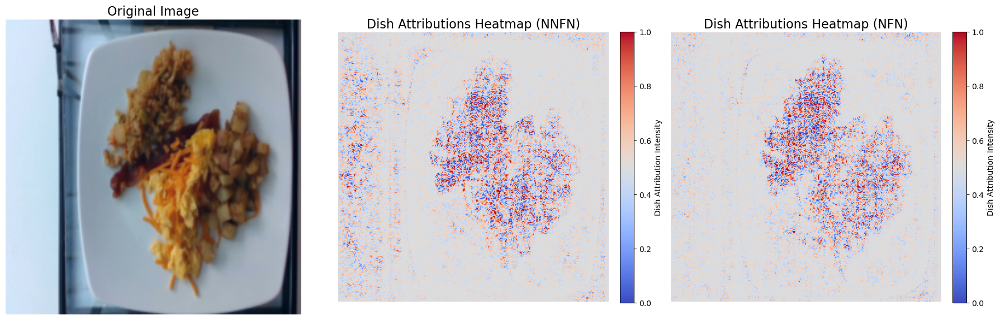

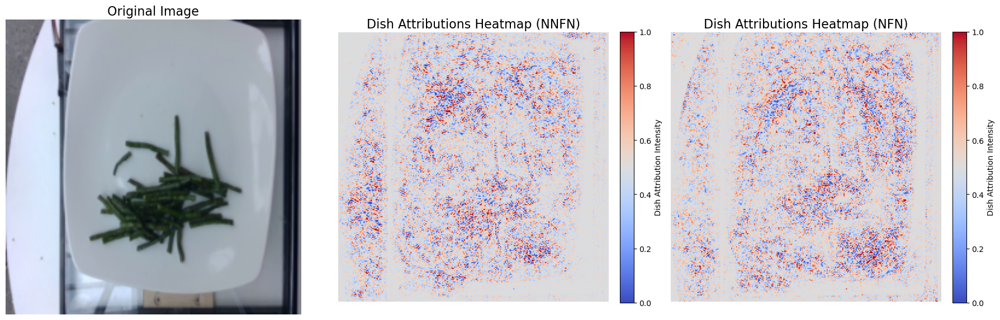

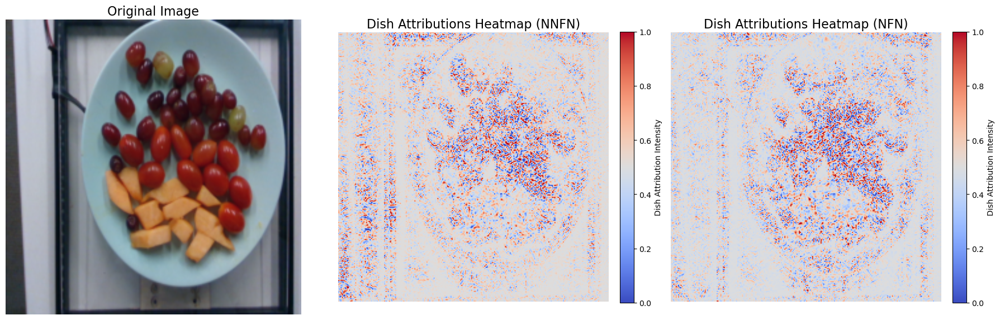

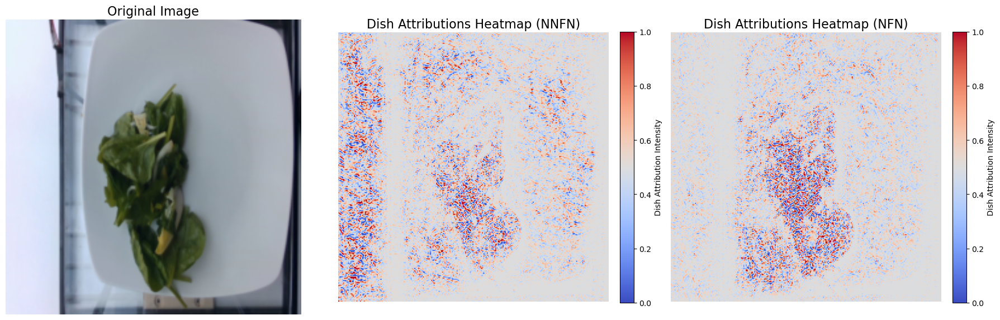

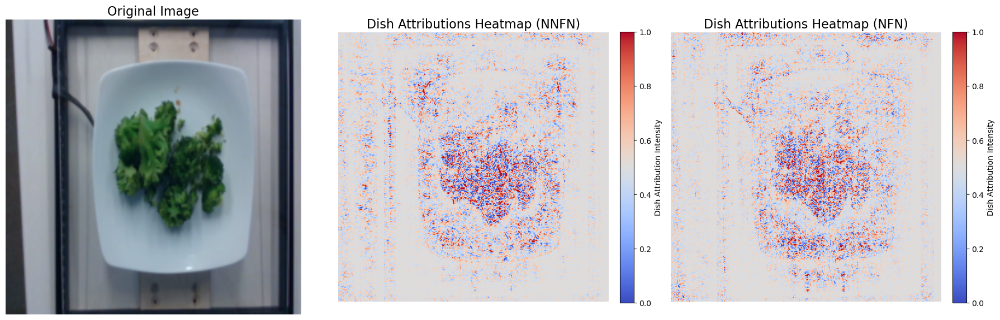

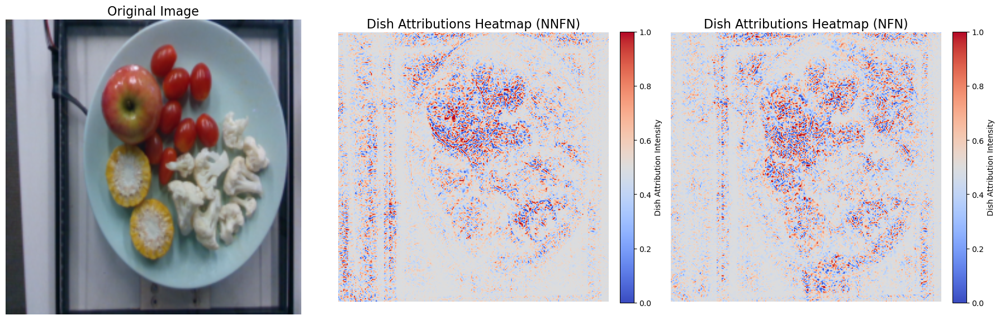

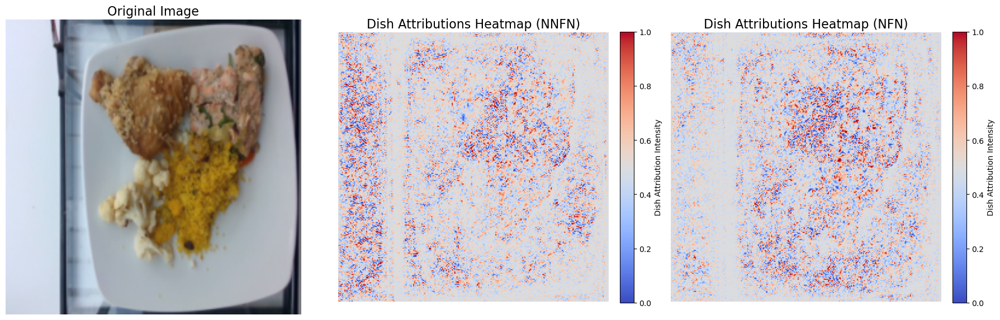

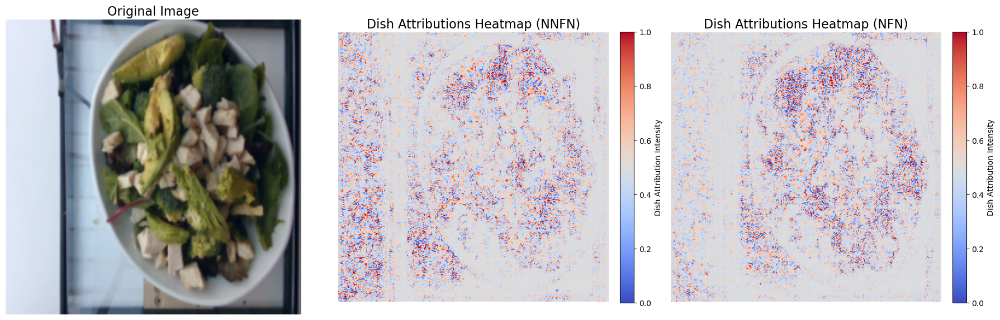

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from captum.attr import IntegratedGradients

# Initialize the wrapped model and the Captum method
gat_dish_ig = IntegratedGradients(gat_dish_wrapped_model)
bert_dish_ig = IntegratedGradients(bert_dish_wrapped_model)


def get_attr(input_image):
    image_input = input_image.unsqueeze(0).to(device)

    baseline = torch.zeros_like(image_input)  # Baseline for Integrated Gradients

    # Compute attributions
    gat_dish_attributions = gat_dish_ig.attribute(inputs=image_input, 
                                        baselines=baseline, 
                                        target=None)
    
    bert_dish_attributions = bert_dish_ig.attribute(inputs=image_input,
                                        baselines=baseline,
                                        target=None)
    
    return gat_dish_attributions, bert_dish_attributions

def visualize_attr(image_input, i):
    # Normalize the original image
    original_image = image_input.squeeze(0).permute(1, 2, 0).cpu().detach().numpy()  # Shape: (224, 224, 3)
    original_image = (original_image - original_image.min()) / (original_image.max() - original_image.min())  # Normalize to [0, 1]

    def process_attr(attr):
        aggregated_attr = attr.squeeze(0).sum(dim=0).cpu().detach().numpy()  # Shape: (224, 224)
        normalized_attr = (aggregated_attr - np.percentile(aggregated_attr, 2)) / (np.percentile(aggregated_attr, 98) - np.percentile(aggregated_attr, 2))
        normalized_attr = np.clip(normalized_attr, 0, 1)  # Clip to [0, 1]
        return normalized_attr

    # Normalize dish attributions
    gat_dish_attributions, bert_dish_attributions = get_attr(image_input)
    
    gat_dish_attributions = process_attr(gat_dish_attributions)
    bert_dish_attributions = process_attr(bert_dish_attributions)

    # Create a single figure with 2 horizontally arranged subplots
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))

    # Plot the original image (First subplot)
    axs[0].imshow(original_image, interpolation='bilinear', alpha=1.0)
    axs[0].axis("off")
    axs[0].set_title("Original Image", fontsize=16)

    # Plot the dish attributions heatmap (Second subplot)
    heatmap = axs[1].imshow(bert_dish_attributions, cmap="coolwarm", alpha=1.0)
    fig.colorbar(heatmap, ax=axs[1], fraction=0.046, pad=0.04, label="Dish Attribution Intensity")
    axs[1].axis("off")
    axs[1].set_title(f"Dish Attributions Heatmap (NNFN)", fontsize=16)

    # Plot the dish attributions heatmap (Second subplot)
    heatmap = axs[2].imshow(gat_dish_attributions, cmap="coolwarm", alpha=1.0)
    fig.colorbar(heatmap, ax=axs[2], fraction=0.046, pad=0.04, label="Dish Attribution Intensity")
    axs[2].axis("off")
    axs[2].set_title(f"Dish Attributions Heatmap (NFN)", fontsize=16)

    # Adjust layout
    plt.tight_layout()
    
    # save image
    if not os.path.exists('./model_intrerpretability'):
        os.makedirs('./model_intrerpretability')
        
    fig.savefig(f'./model_intrerpretability/{sampled_images[i]}_attn.png', dpi=300, bbox_inches='tight')
    plt.show()
    
for i, input_image in enumerate(input_images):
    visualize_attr(input_image, i)